## **Netflix Movies and TV Shows Analysis**

In [1]:
# Importing required Python libraries for data analysis and visualization

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Loading the Netflix dataset into a Pandas DataFrame

df = pd.read_csv("netflix_titles.csv")

In [3]:
# Displaying the first five rows of the dataset

df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [4]:
# Checking the number of rows and columns

df.shape

(8807, 12)

In [5]:
# Checking dataset information and data types

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB


In [6]:
# Generating statistical summary of numerical columns

df.describe()

,release_year
count,8807.000000
mean,2014.180198
std,8.819312
min,1925.000000
25%,2013.000000
50%,2017.000000
75%,2019.000000
max,2021.000000


## **Data Exploration**

In [7]:
# Checking the number of missing values in each column

df.isna().sum()

show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64

In [8]:
# Checking for duplicate records in the dataset

df.duplicated().sum()

np.int64(0)

In [9]:
# Converting date_added column to datetime format

df["date_added"] = pd.to_datetime(df["date_added"], errors="coerce")

# Extracting the year in which the content was added to Netflix

df["year_added"] = df["date_added"].dt.year

In [10]:
# Counting the number of Movies and TV Shows

type_count = df["type"].value_counts()

type_count

type
Movie      6131
TV Show    2676
Name: count, dtype: int64

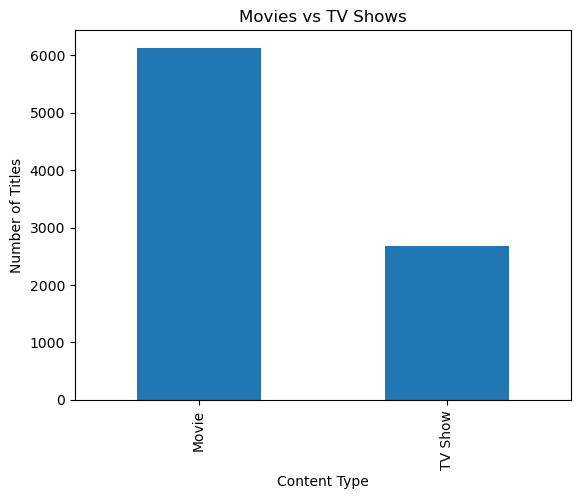

In [11]:
# Visualizing the distribution of Movies and TV Shows

type_count.plot(kind="bar")

plt.xlabel("Content Type")
plt.ylabel("Number of Titles")
plt.title("Movies vs TV Shows")

plt.show()

## **Content Analysis**

In [12]:
# Counting the number of titles added to Netflix each year

year_added_count = df["year_added"].value_counts().sort_index()

year_added_count

year_added
2008.0       2
2009.0       2
2010.0       1
2011.0      13
2012.0       3
2013.0      10
2014.0      23
2015.0      73
2016.0     418
2017.0    1164
2018.0    1625
2019.0    1999
2020.0    1878
2021.0    1498
Name: count, dtype: int64

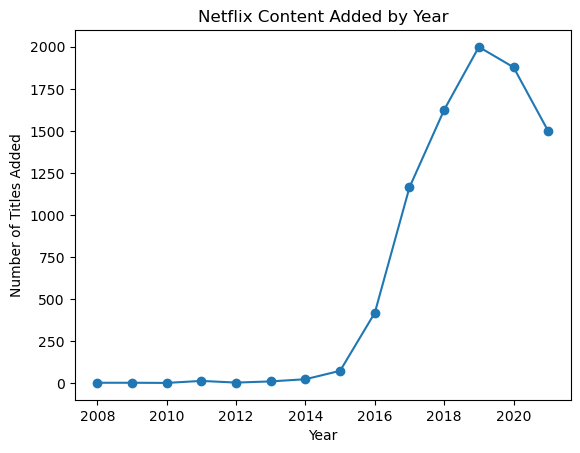

In [13]:
# Visualizing the number of titles added to Netflix each year

year_added_count.plot(kind="line", marker="o")

plt.xlabel("Year")
plt.ylabel("Number of Titles Added")
plt.title("Netflix Content Added by Year")

plt.show()

In [14]:
# Counting the number of titles by their original release year

release_year_count = df["release_year"].value_counts().sort_index()

release_year_count.tail(20)

release_year
2002      51
2003      61
2004      64
2005      80
2006      96
2007      88
2008     136
2009     152
2010     194
2011     185
2012     237
2013     288
2014     352
2015     560
2016     902
2017    1032
2018    1147
2019    1030
2020     953
2021     592
Name: count, dtype: int64

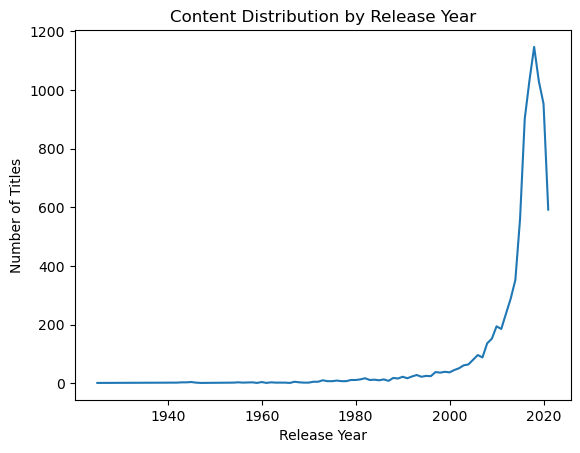

In [15]:
# Visualizing the distribution of content by release year

release_year_count.plot(kind="line")

plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.title("Content Distribution by Release Year")

plt.show()

In [16]:
# Splitting multiple countries and counting titles for each country

country_count = (df["country"].dropna().str.split(", ").explode().value_counts())

country_count.head(10)

country
United States     3689
India             1046
United Kingdom     804
Canada             445
France             393
Japan              318
Spain              232
South Korea        231
Germany            226
Mexico             169
Name: count, dtype: int64

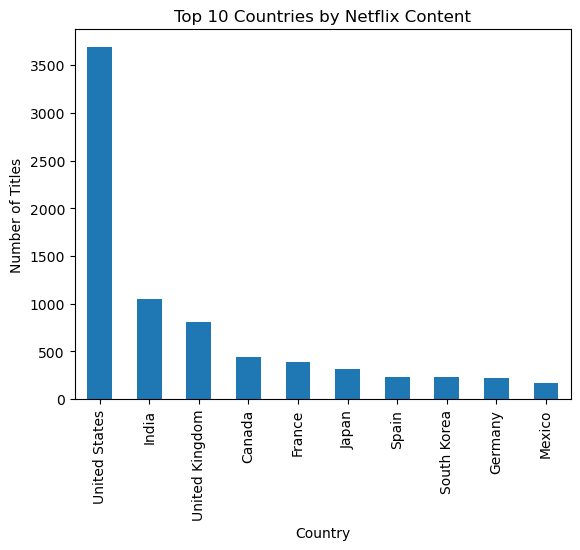

In [18]:
# Visualizing the top 10 countries producing Netflix content

country_count.head(10).plot(kind="bar")

plt.xlabel("Country")
plt.ylabel("Number of Titles")
plt.title("Top 10 Countries by Netflix Content")
plt.show()

## **Genre and Rating Analysis**

In [19]:
# Splitting multiple genres and counting titles for each genre

genre_count = (df["listed_in"].str.split(", ").explode().value_counts())

genre_count.head(10)

listed_in
International Movies        2752
Dramas                      2427
Comedies                    1674
International TV Shows      1351
Documentaries                869
Action & Adventure           859
TV Dramas                    763
Independent Movies           756
Children & Family Movies     641
Romantic Movies              616
Name: count, dtype: int64

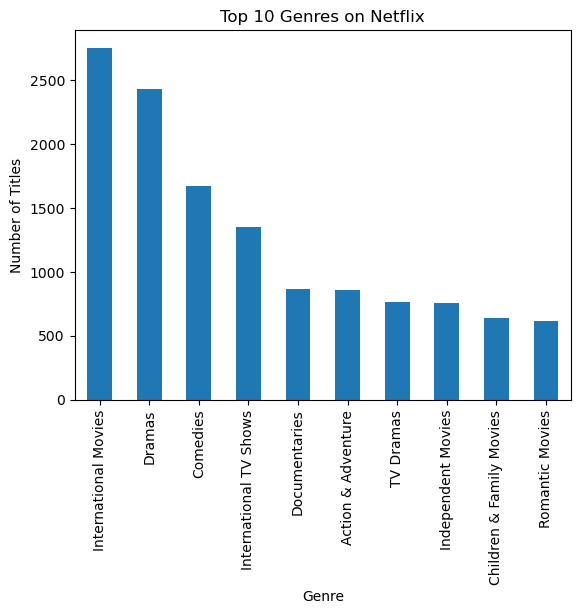

In [20]:
# Visualizing the top 10 genres on Netflix

genre_count.head(10).plot(kind="bar")

plt.xlabel("Genre")
plt.ylabel("Number of Titles")
plt.title("Top 10 Genres on Netflix")

plt.show()

In [21]:
# Identifying invalid values present in the rating column

invalid_ratings = ["74 min", "84 min", "66 min"]

# Replacing invalid rating values with missing values

df["rating"] = df["rating"].replace(invalid_ratings, pd.NA)

# Checking the cleaned rating distribution

df["rating"].value_counts()

rating
TV-MA       3207
TV-14       2160
TV-PG        863
R            799
PG-13        490
TV-Y7        334
TV-Y         307
PG           287
TV-G         220
NR            80
G             41
TV-Y7-FV       6
NC-17          3
UR             3
Name: count, dtype: int64

In [22]:
# Counting the number of titles for each rating

rating_count = df["rating"].value_counts()

rating_count

rating
TV-MA       3207
TV-14       2160
TV-PG        863
R            799
PG-13        490
TV-Y7        334
TV-Y         307
PG           287
TV-G         220
NR            80
G             41
TV-Y7-FV       6
NC-17          3
UR             3
Name: count, dtype: int64

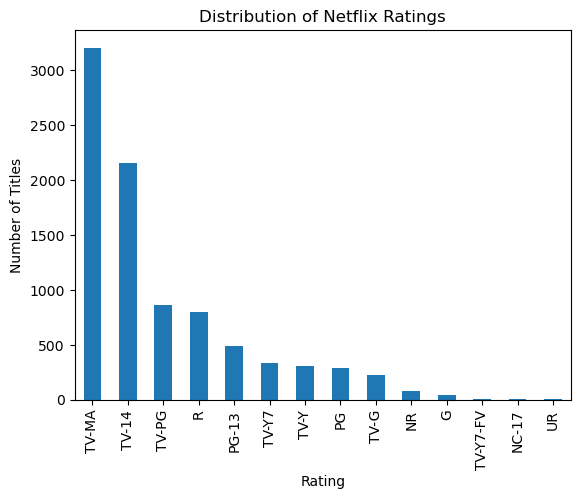

In [23]:
# Visualizing the distribution of Netflix ratings

rating_count.plot(kind="bar")

plt.xlabel("Rating")
plt.ylabel("Number of Titles")
plt.title("Distribution of Netflix Ratings")

plt.show()

In [24]:
# Separating duration values for Movies and TV Shows

movie_duration = df[df["type"] == "Movie"]["duration"].dropna()

tv_duration = df[df["type"] == "TV Show"]["duration"].dropna()

In [25]:
# Extracting movie duration in minutes

movie_minutes = movie_duration.str.replace(" min", "", regex=False).astype(int)

movie_minutes.describe()

count    6128.000000
mean       99.577187
std        28.290593
min         3.000000
25%        87.000000
50%        98.000000
75%       114.000000
max       312.000000
Name: duration, dtype: float64

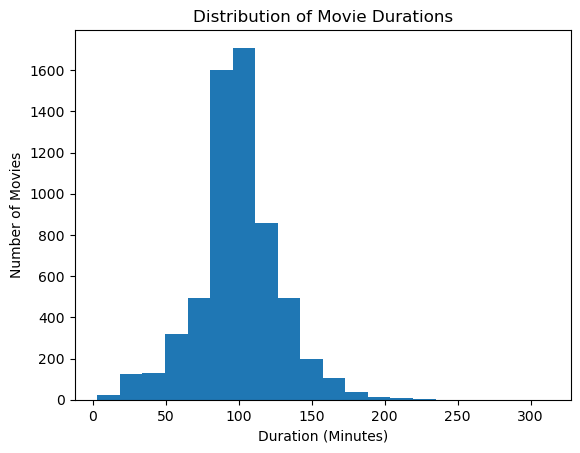

In [26]:
# Visualizing the distribution of movie durations

movie_minutes.plot(kind="hist", bins=20)

plt.xlabel("Duration (Minutes)")
plt.ylabel("Number of Movies")
plt.title("Distribution of Movie Durations")

plt.show()

In [27]:
# Extracting the number of seasons for TV Shows

tv_seasons = tv_duration.str.replace(" Season", "", regex=False)

tv_seasons = tv_seasons.str.replace("s", "", regex=False).astype(int)

tv_seasons.value_counts().sort_index()

duration
1     1793
2      425
3      199
4       95
5       65
6       33
7       23
8       17
9        9
10       7
11       2
12       2
13       3
15       2
17       1
Name: count, dtype: int64

## **Conclusion**

Netflix has more Movies than TV Shows, with the United States being the largest content-producing country. International Movies, Dramas, and Comedies are among the most common categories, while TV-MA is the most common rating.
The analysis also shows that Netflix added the highest number of titles in 2019, and most TV Shows in the dataset have only one season.

**Complete Project on GitHub:** https://github.com/DIVYAGHODE/Python-Netflix-Movies-and-TV-Shows-Project